# Практичне завдання 3: TF-IDF зважені ембединги для детекції AI-текстів
Порівняння Mean Pooling та TF-IDF Weighted Mean над FastText-векторами для бінарної класифікації `ai` / `human` (SVM, Logistic Regression, KNN).

## 0. Встановлення залежностей

In [39]:
%pip install spacy 
%pip install gensim
%pip install pandas
%pip install scikit-learn
%pip install numpy
%pip install umap-learn
!python -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 2.8 MB/s eta 0:00:05
     ---- ----------------------------------- 1.3/12.8 MB 2.4 MB/s eta 0:00:05
     ----- ---------------------------------- 1.8/12.8 MB 2.4 MB/s eta 0:00:05
     ------- -------------------------------- 2.4/12.8 MB 2.5 MB/s eta 0:00:05
     --------- ------------------------------ 3.1/12.8 MB 2.7 MB/s eta 0:00:04
     ----------- ---------------------------- 3.7/12.8 MB 2.7 MB/

### Імпорти та фіксація random seed

In [40]:
import pandas as pd
import numpy as np

random_seed = 42

## 1. Завантаження даних
Завантаження опрацьованих даних із `data.csv` (стовпці `text_content` — текст, `label` — клас: `ai` / `human`).

In [41]:
data = pd.read_csv("data.csv")

## 2. Попередня обробка тексту (spaCy)
Лематизація, приведення до нижнього регістру, видалення стоп-слів і небуквених токенів; токенізація.

In [42]:
import spacy

nlp = spacy.load("en_core_web_sm")

def preprocess_corpus(texts, batch_size=256):
    tokenized_corpus = []
    for doc in nlp.pipe(texts, batch_size=batch_size, n_process=-1):
        tokens = [
            token.lemma_.lower() 
            for token in doc 
            if token.is_alpha and not token.is_stop
        ]
        tokenized_corpus.append(tokens)
    return tokenized_corpus

data["tokens"] = preprocess_corpus(data["text_content"])

## 3. Видалення дублікатів
Дублікатами вважаються тексти з однаковим набором токенів (ключ — відсортований список токенів). Видаляються лише точні збіги «мішка слів»; тексти, що відрізняються навіть одним токеном, залишаються. Вивід — кількість видалених рядків.

In [43]:
data["tok_key"] = data["tokens"].map(lambda t: " ".join(sorted(t)))

before = len(data)
data = data.drop_duplicates(subset="tok_key").reset_index(drop=True)
print("видалено:", before - len(data))

видалено: 75


## 4. Розбиття на train / test
Стратифіковане розбиття 80 / 20 (`random_state=42`). Розбиття виконується після видалення дублікатів.

In [44]:
from sklearn.model_selection import train_test_split
X = data["tokens"]
y = data["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_seed
)

## 5. Навчання FastText
Модель навчається лише на train-корпусі (skip-gram, розмірність 100, вікно 5, `min_count=2`), щоб тестові тексти не впливали на ембединги.

In [45]:
from gensim.models import FastText

model = FastText(
    sentences= X_train.tolist(),
    vector_size = 100,
    window = 5,
    min_count = 2,
    sg = 1,
    workers = 4,
    seed = random_seed
)

## 6. Функції агрегації документних векторів
`mean_pooling` — просте середнє векторів слів; `TFIDF_weighted_pooling` — середнє, зважене TF-IDF (формула (6) із завдання).

In [46]:
def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis = 0)

def TFIDF_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []

    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    weights /= weights.sum()
    return np.average(vectors, axis = 0, weights = weights)

## 7. Класифікатори
SVM (RBF-ядро), Logistic Regression, KNN (k = 5).

In [47]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, roc_auc_score)

classifiers = {
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'LogReg': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

## 8. Векторизація документів
IDF рахується лише на train (терми з df ≥ 2), TF — окремо для кожного документа. Далі train і test перетворюються у вектори обома методами агрегації. Вивід — розмір словника IDF та форми матриць (документи × 100).

In [ ]:
from collections import Counter

def build_idf(corpus, min_df=2):
    n_docs = len(corpus)
    doc_freq = Counter()
    for tokens in corpus:
        doc_freq.update(set(tokens))
    return {t: np.log(n_docs / c) for t, c in doc_freq.items() if c >= min_df}

def document_tfidf(tokens, idf_scores):
    if not tokens:
        return {}
    term_freq = Counter(tokens)
    n = len(tokens)
    return {t: (cnt / n) * idf_scores[t] for t, cnt in term_freq.items() if t in idf_scores}

idf_scores = build_idf(X_train, min_df=2)
print(f"Розмір словника IDF: {len(idf_scores)}")

def vectorize_corpus(token_lists, model, idf_scores, method="mean"):
    if method == "mean":
        return np.array([mean_pooling(toks, model) for toks in token_lists])
    if method == "tfidf":
        vectors = []
        for toks in token_lists:
            doc_tfidf = document_tfidf(toks, idf_scores)
            vectors.append(TFIDF_weighted_pooling(toks, model, doc_tfidf))
        return np.array(vectors)
    raise ValueError(f"Невідомий метод агрегації: {method}")

X_train_mean  = vectorize_corpus(X_train, model, idf_scores, method="mean")
X_test_mean   = vectorize_corpus(X_test,  model, idf_scores, method="mean")
X_train_tfidf = vectorize_corpus(X_train, model, idf_scores, method="tfidf")
X_test_tfidf  = vectorize_corpus(X_test,  model, idf_scores, method="tfidf")

print("Mean Pooling:          ", X_train_mean.shape, X_test_mean.shape)
print("TF-IDF Weighted Mean:  ", X_train_tfidf.shape, X_test_tfidf.shape)

Розмір словника IDF: 508
Mean Pooling:           (693, 100) (174, 100)
TF-IDF Weighted Mean:   (693, 100) (174, 100)


## 9. Оцінка якості
Класи кодуються як `ai` → 0, `human` → 1; клас 1 (`human`) вважається позитивним для ROC-AUC та PR-AUC.

In [49]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)
from sklearn.preprocessing import LabelEncoder
import pandas as pd

label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_test_enc = label_encoder.transform(y_test)
print(
    "Кодування класів:",
    dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))),
)


def evaluate_classifier(clf, X_tr, y_tr, X_te, y_te, name):
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    if hasattr(clf, "predict_proba"):
        y_score = clf.predict_proba(X_te)[:, 1]
    else:
        y_score = clf.decision_function(X_te)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "F1-macro": f1_score(y_te, y_pred, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_score),
        "PR-AUC": average_precision_score(y_te, y_score),
    }


vectorized = {
    "Mean Pooling": (X_train_mean, X_test_mean),
    "TF-IDF Weighted Mean": (X_train_tfidf, X_test_tfidf),
}

results = []
for agg_name, (Xtr, Xte) in vectorized.items():
    for clf_name, clf in classifiers.items():
        clf_fresh = clone(clf)
        m = evaluate_classifier(
            clf_fresh, Xtr, y_train_enc, Xte, y_test_enc, clf_name
        )
        m["Aggregation"] = agg_name
        results.append(m)

columns_order = [
    "Aggregation",
    "Model",
    "Accuracy",
    "F1-macro",
    "Balanced Accuracy",
    "ROC-AUC",
    "PR-AUC",
]
results_df = pd.DataFrame(results)[columns_order]
print(results_df.to_string(index=False))

Кодування класів: {'ai': 0, 'human': 1}


c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


         Aggregation  Model  Accuracy  F1-macro  Balanced Accuracy  ROC-AUC   PR-AUC
        Mean Pooling    SVM  0.885057  0.885057           0.894631 0.917601 0.957785
        Mean Pooling LogReg  0.810345  0.810188           0.816106 0.878873 0.924918
        Mean Pooling    KNN  1.000000  1.000000           1.000000 1.000000 1.000000
TF-IDF Weighted Mean    SVM  0.902299  0.902270           0.910256 0.921608 0.959642
TF-IDF Weighted Mean LogReg  0.821839  0.821550           0.826522 0.883280 0.927543
TF-IDF Weighted Mean    KNN  1.000000  1.000000           1.000000 1.000000 1.000000


**Таблиця 1.** Метрики якості на тестовій вибірці (174 документи) для двох методів агрегації та трьох класифікаторів.

**Аналіз таблиці 1.** Якщо розглядати якість моделей, навчених на різних типах агрегацій, то по основних метриках(F1 та PR-AUC)(є невеликий дисбаланс класів), TF-IDF незначно кращий за пулінг середнім: для SVC, навченої на Mean Pooling, F1 i PR-AUC = 0.885057 та 0.957785 відповідно, тоді як для такої ж моделі, навченої на TF-IDF, вони становлять 0.902270 та 0.959642, тобто F1 зріс на ~1.7 в.п., а PR-AUC лише на ~0.2 в.п. Для LogReg, навченої на Mean Pooling, F1 i PR-AUC = 0.810188 та 0.924918 відповідно, тоді як для такої ж моделі, навченої на TF-IDF, вони становлять 0.821550 та 0.927543, тобто F1 зріс на ~1.1 в.п., а PR-AUC на ~0.3 в.п. Особливо цікавою є ситуація з KNN моделями: вони показали найвищий можливий результат: 100% для усіх метрик. Можна сказати, що причиною цього може стати щонайперше це невиявлений data leakage, а інший - природа самих векторизованих даних та роботи KNN: векторизовані дані це репрезентація даних у просторі, а KNN є орієнтованою на простір та знаходження просторових угрупувань, але щоб точно це довести це, треба розглянити просторове представлення класів

Розміри вибірок (кількість документів): перша комірка — train, друга — test.

In [50]:
len(X_train)

693

In [51]:
len(X_test)

174

## 10. Проєкції t-SNE та UMAP
**Рис. 1–3.** Для кожного класифікатора окремий малюнок: рядки — метод агрегації, стовпці — метод проєкції (косинусна метрика, train і test проєктуються разом). Сірі точки — train, сині — test, класифікований правильно, червоні хрести — помилки класифікатора. Колір позначає правильність передбачення, а не клас документа.

c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


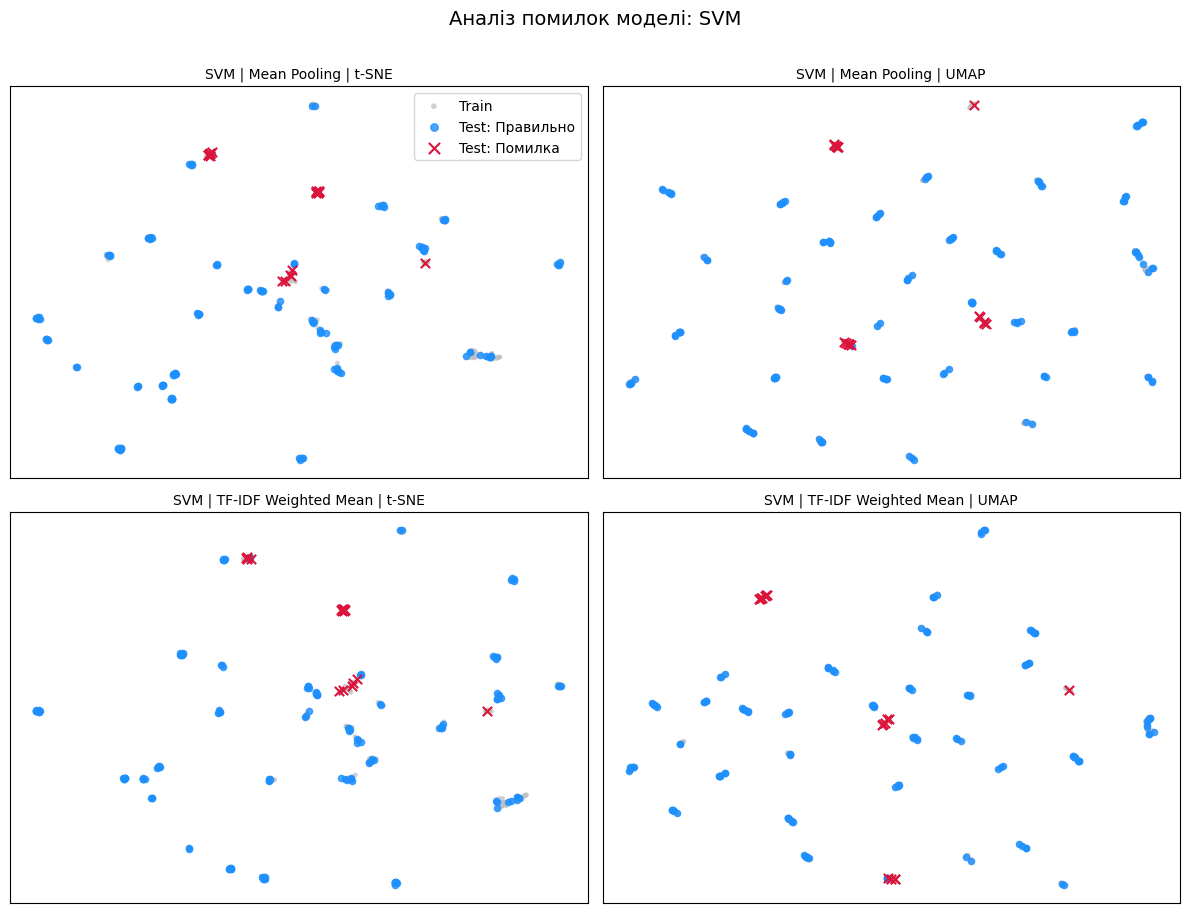

c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


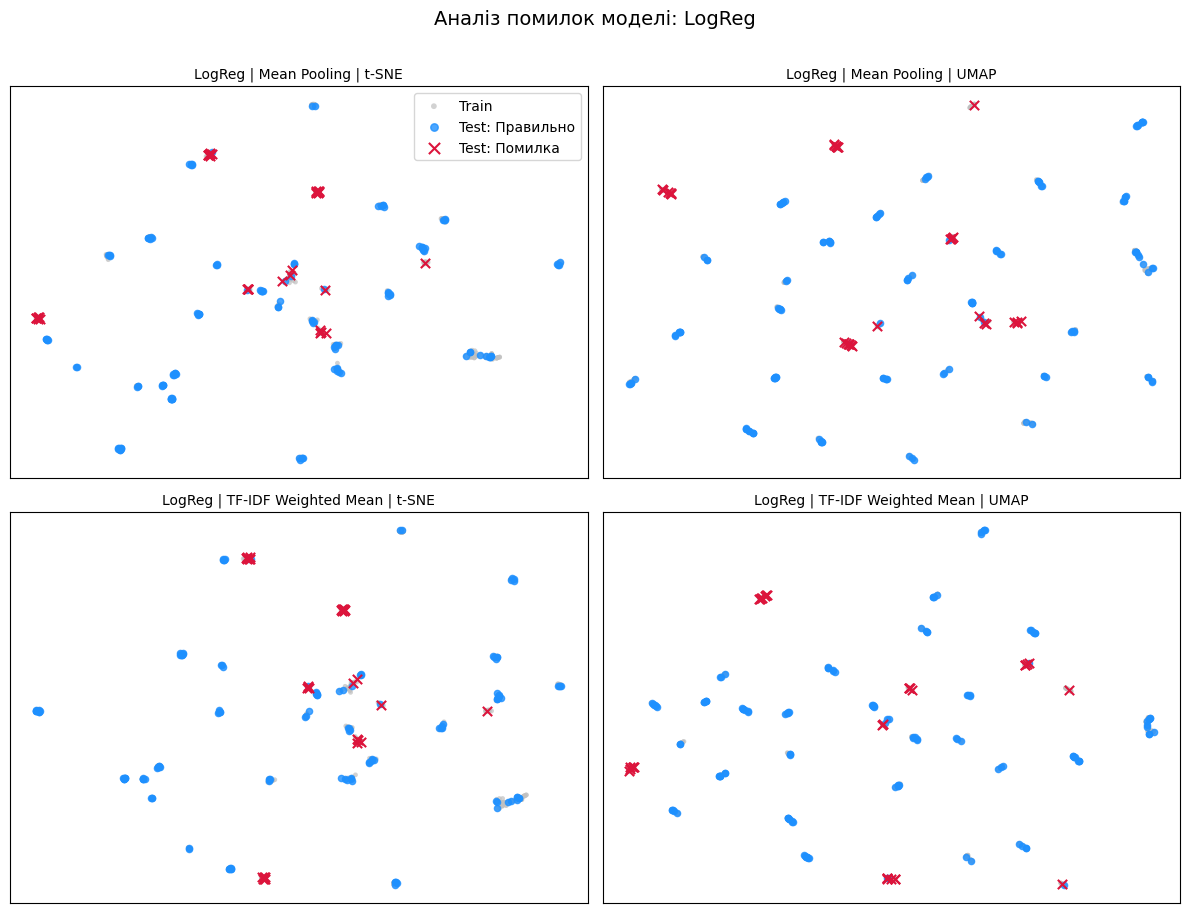

c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


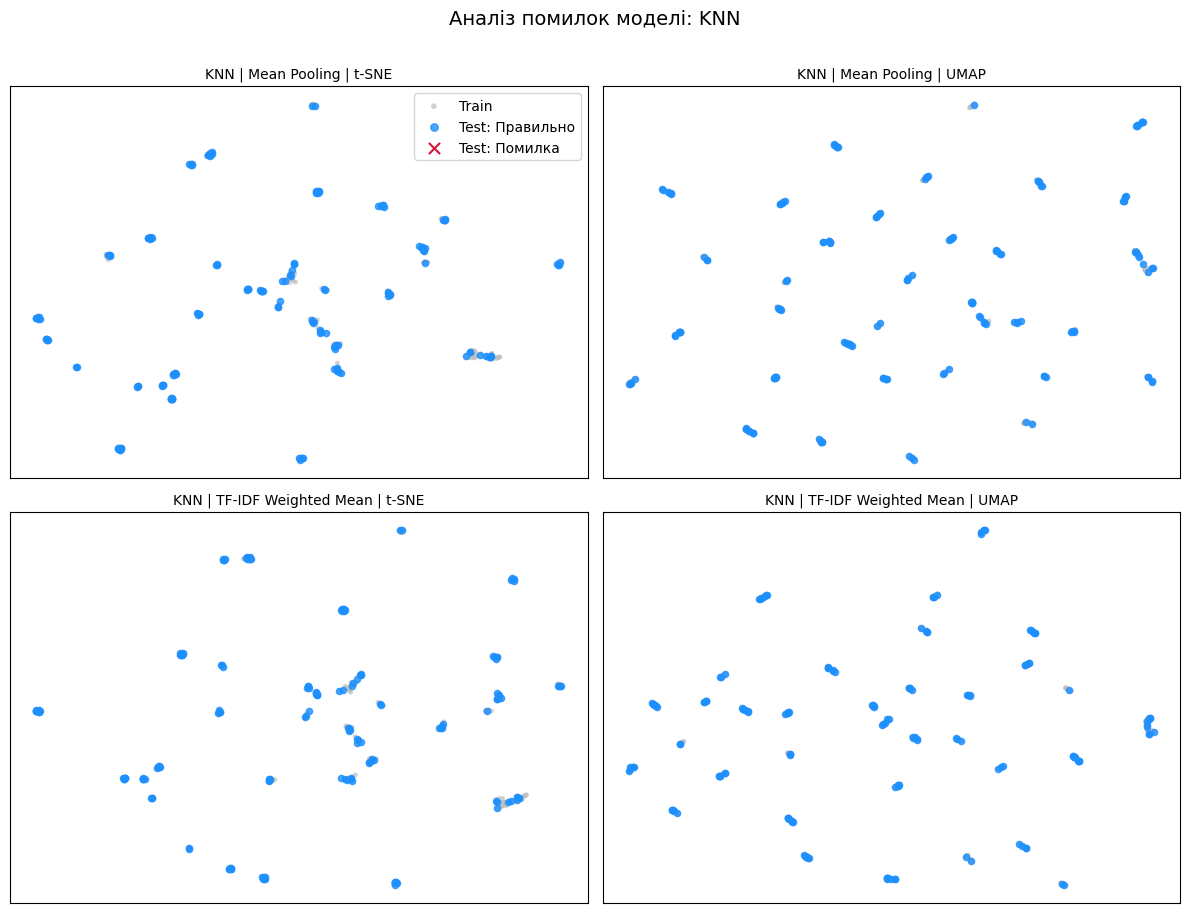

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.base import clone
from sklearn.manifold import TSNE
from umap import UMAP

reducers = {
    "t-SNE": TSNE(n_components=2, perplexity=30, random_state=42, metric="cosine"),
    "UMAP": UMAP(
        n_components=2, n_neighbors=15, min_dist=0.1, random_state=42, metric="cosine"
    ),
}

for clf_name, clf in classifiers.items():
    fig, axes = plt.subplots(
        nrows=len(vectorized),
        ncols=len(reducers),
        figsize=(12, 4.5 * len(vectorized)),
        squeeze=False,
    )

    for row_idx, (agg_name, (Xtr, Xte)) in enumerate(vectorized.items()):
        fitted_clf = clone(clf)  
        fitted_clf.fit(Xtr, y_train_enc)
        y_pred = fitted_clf.predict(Xte)

        correct_mask = y_pred == y_test_enc

        n_train = len(Xtr)
        X_all = np.vstack([Xtr, Xte])

        for col_idx, (red_name, red) in enumerate(reducers.items()):
            ax = axes[row_idx, col_idx]

            X_all_2d = clone(red).fit_transform(X_all)

            Xtr_2d = X_all_2d[:n_train]
            Xte_2d = X_all_2d[n_train:]

            ax.scatter(
                Xtr_2d[:, 0],
                Xtr_2d[:, 1],
                c="silver",
                label="Train",
                alpha=0.7,
                s=12,
                edgecolors="none",
            )

            ax.scatter(
                Xte_2d[correct_mask, 0],
                Xte_2d[correct_mask, 1],
                c="dodgerblue",
                label="Test: Правильно",
                alpha=0.8,
                s=20,
            )

            ax.scatter(
                Xte_2d[~correct_mask, 0],
                Xte_2d[~correct_mask, 1],
                c="crimson",
                label="Test: Помилка",
                alpha=1.0,
                s=45,
                marker="x",
                linewidths=1.5,
            )

            ax.set_title(f"{clf_name} | {agg_name} | {red_name}", fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel(f"{red_name} 1", fontsize=9)
            ax.set_ylabel(f"{red_name} 2", fontsize=9)

            if row_idx == 0 and col_idx == 0:
                ax.legend(loc="best", markerscale=1.2)

    plt.suptitle(
        f"Аналіз помилок моделі: {clf_name}", fontsize=14, y=1.01
    )
    plt.tight_layout()
    plt.show()

**Аналіз рис. 1–3.** На проєкціях t-SNE та UMAP видно багато щільних дрібних кластерів при лише двох класах. Тобто кожен клас складається з багатьох окремих груп, які в просторі чергуються з групами іншого класу. Лінійна модель (LogReg) має розділити такі дані однією гіперплощиною, тому вона поступається іншим моделям: її помилки зосереджені в кількох кластерах, що лежать поруч із кластерами протилежного класу. SVM з RBF-ядром та KNN працюють локально, тому добре підходять для такої структури. KNN показав ідеальний результат (1.0) ще й тому, що тестові документи майже збігаються з train-документами: на графіках тестові точки лежать поверх навчальних, тож найближчий сусід майже завжди має правильний клас. Це також означає, що отримані метрики можуть бути завищеними порівняно з реальною якістю на нових даних.

## 11. Матриці помилок
**Рис. 4.** Матриці помилок на тестовій вибірці: рядки — справжній клас, стовпці — передбачений (0 = `ai`, 1 = `human`). Верхній рядок — Mean Pooling, нижній — TF-IDF Weighted Mean.

c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\vital\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


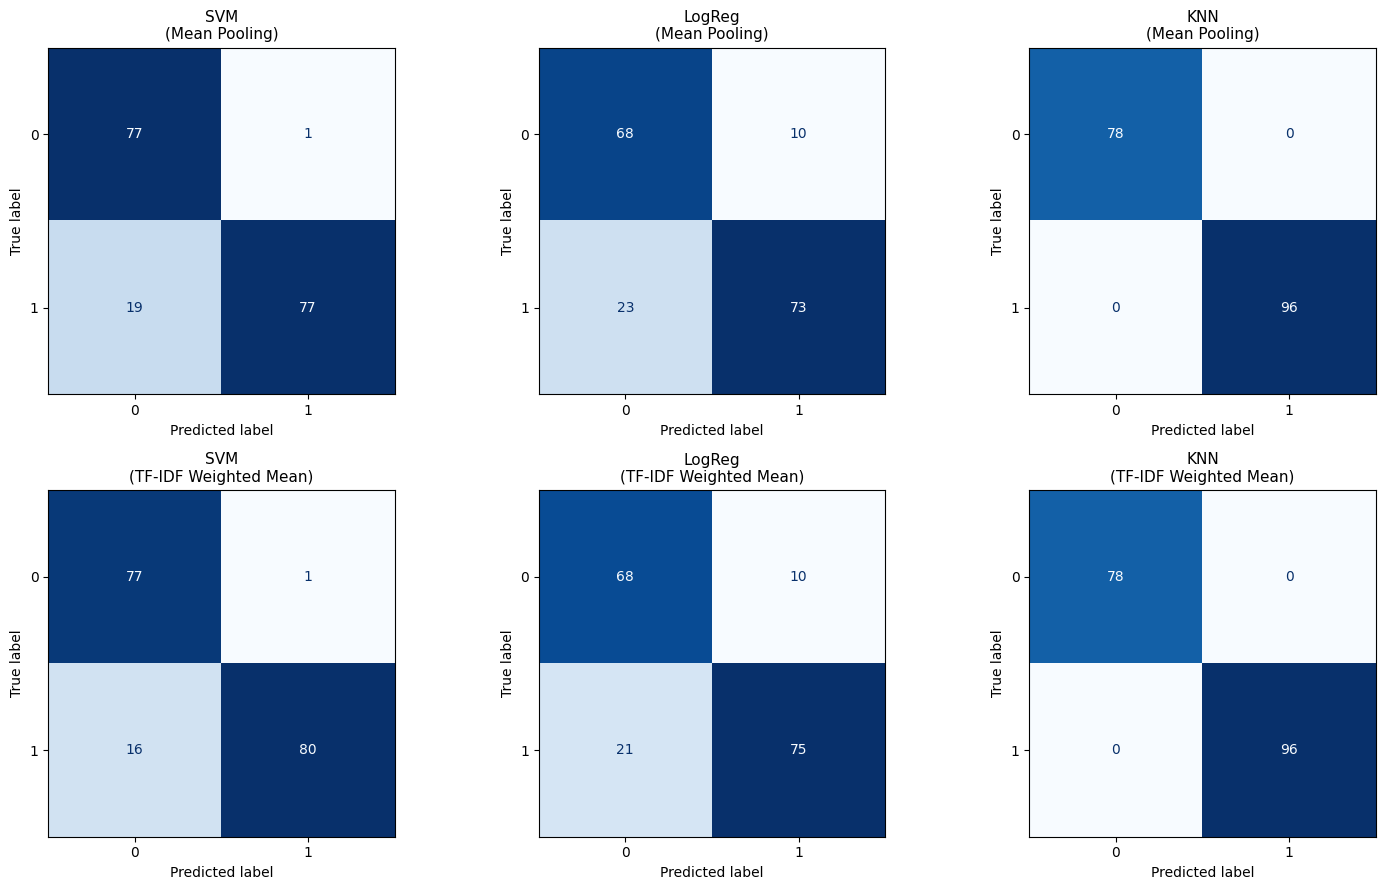

In [53]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

n_rows = len(vectorized)
n_cols = len(classifiers)

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(5 * n_cols, 4.5 * n_rows),
    squeeze=False,
)

for row_idx, (agg_name, (Xtr, Xte)) in enumerate(vectorized.items()):
    for col_idx, (clf_name, clf) in enumerate(classifiers.items()):
        clf_fresh = clone(clf)
        clf_fresh.fit(Xtr, y_train_enc)
        y_pred = clf_fresh.predict(Xte)

        matrix = confusion_matrix(y_test_enc, y_pred)
        ax = axes[row_idx, col_idx]

        disp = ConfusionMatrixDisplay(
            confusion_matrix=matrix, display_labels=label_encoder.classes_
        )
        disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)

        ax.set_title(f"{clf_name}\n({agg_name})", fontsize=11)
        ax.set_xlabel("Передбачений клас")
        ax.set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

**Аналіз рис. 4.** На матрицях помилок видно, що KNN класифікує всі тестові документи правильно (78/78 і 96/96) для обох методів агрегації. SVM помиляється майже виключно в один бік: майже всі документи класу 0 розпізнані правильно (77 з 78), але 19 документів класу 1 (16 при TF-IDF) помилково віднесені до класу 0. Отже, SVM має високу точність за класом 1 (лише 1 хибнопозитивне передбачення), але нижчу повноту (0.80 при Mean Pooling і 0.83 при TF-IDF). Це дає accuracy 0.885 і 0.902 відповідно.

LogReg показує найгірший результат: 10 хибнопозитивних і 23 хибнонегативних передбачень при Mean Pooling (accuracy 0.810) та 10 і 21 при TF-IDF (accuracy 0.822). На відміну від SVM, його помилки є в обох напрямках, хоча хибнонегативних усе одно більше.

TF-IDF зважування трохи покращує результат: кількість пропущених документів класу 1 зменшується (у SVM з 19 до 16, у LogReg з 23 до 21), а кількість хибнопозитивних не змінюється. Різниця невелика, і на KNN вона не впливає.

Порядок моделей (KNN > SVM > LogReg) узгоджується з аналізом проєкцій t-SNE та UMAP: дані утворюють багато щільних кластерів при лише двох класах, тому локальні методи (KNN, SVM з RBF-ядром) працюють краще за лінійну LogReg. Водночас ідеальний результат KNN слід інтерпретувати обережно: тестові документи лежать дуже близько до навчальних, тому метрики можуть бути завищеними порівняно з реальною якістю на нових даних.

## 12. Лінгвістичний аналіз: топ-терми класу AI
**Таблиця 2.** 15 термів (уніграми та біграми, біграми враховуються при `min_df=3`) з найбільшим середнім TF-IDF серед AI-документів train. Значення — середній TF-IDF терму по всіх AI-документах. У топ-15 потрапили лише уніграми.

In [ ]:
from collections import defaultdict

AI_LABEL = "ai" 

def add_bigrams(tokens):
    return tokens + [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]

ngram_train = [add_bigrams(t) for t in X_train]
idf_ng = build_idf(ngram_train, min_df=3)

ai_docs = [doc for doc, lab in zip(ngram_train, y_train) if lab == AI_LABEL]

sum_tfidf = defaultdict(float)
for doc in ai_docs:
    for term, w in document_tfidf(doc, idf_ng).items():
        sum_tfidf[term] += w

mean_tfidf_ai = {t: s / len(ai_docs) for t, s in sum_tfidf.items()}


top = sorted(mean_tfidf_ai.items(), key=lambda x: x[1], reverse=True)[:15]
print(f"{'Терм / n-грама':<30} | Середній TF-IDF")
print("-" * 50)
for term, score in top:
    print(f"{term:<30} | {score:.5f}")

Терм / n-грама                 | Середній TF-IDF
--------------------------------------------------
think                          | 0.01646
conversation                   | 0.01341
potential                      | 0.01090
follow                         | 0.01087
progress                       | 0.01087
point                          | 0.01085
read                           | 0.01052
challenge                      | 0.01050
recommend                      | 0.01034
engage                         | 0.01016
exhausting                     | 0.01010
acknowledge                    | 0.01010
complexity                     | 0.01010
instead                        | 0.01010
reduce                         | 0.01010


## 13. Відповіді на дослідницькі питання

1. При простому Mean Pooling високу вагу мають високочастотні слова (прийменники, службові слова, загальна лексика), вектори яких з'являються практично в кожному документі. Через це середні вектори всіх документів сильно стягуються в напрямку цього «шумового центру» простору ембеддингів, утворюючи вузький конус із надвисокою косинусною подібністю між геть різними текстами.TF-IDF зважування дає загальним словам вагу, близьку до $0$, що «висмикує» вектори документів із центру шуму та розносить їх уздовж напрямків їхніх справжніх ключових слів.
2. KNN
3. 